# F2 — Análisis Exploratorio de Datos (EDA)

Objetivo: entender la calidad y estructura de los datos extraídos de [vlr.gg](https://www.vlr.gg/)
y detectar qué señales son útiles para predecir el **ganador** de un partido profesional
de Valorant (target binario `y`: `1` = gana `team1`, `0` = gana `team2`).

Estructura:
1. Carga y calidad de datos (nulos, duplicados, fechas, scores).
2. Análisis univariado (partidos por año/mes, eventos, equipos, rating/ranking).
3. Análisis bivariado / señales (balance del target, win rate, head-to-head, marcadores).
4. Relación features ↔ target (correlaciones y distribuciones).
5. Conclusiones preliminares y sugerencias para F3/F4.

Código reutilizable: `src/eda.py` (funciones de carga y helpers de plot).

## 0. Imports, rutas y carga de tablas

La variable `DATA_DIR` define dónde están los datos. Ajústala según el entorno:
- **Local**: `data` (como aquí).
- **Colab/Drive**: apunta a tu carpeta montada, p. ej. `/content/drive/MyDrive/valorant-data`.

In [1]:
# Monta Google Drive (solo en Colab) para acceder a los datos y a src/.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # fuera de Colab (local)


Mounted at /content/drive


In [2]:
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# Asegurar que src/ esté en el path (local o Colab)
ROOT = Path("/content/drive/MyDrive/Analisis de datos/Proyecto final")
if not ROOT.exists():
    ROOT = Path.cwd()  # fallback local
if (ROOT / "src").exists():
    sys.path.insert(0, str(ROOT / "src"))

from eda import (
    load_tables, parse_dates, valid_dates_mask, is_placeholder,
    win_rate_by_team, head_to_head_matrix,
    apply_style, plot_target_balance, plot_corr_heatmap, plot_feature_vs_target,
    COLOR_TEAM1, COLOR_TEAM2, COLOR_NEUTRAL,
)

# Ruta a los datos (ajústala en Colab/Drive)
DATA_DIR = str(ROOT / "data")
if not Path(DATA_DIR).exists():
    DATA_DIR = str(ROOT / "data")  # fallback al espejo local del repo

apply_style()
print("DATA_DIR =", DATA_DIR)

DATA_DIR = /content/drive/MyDrive/Analisis de datos/Proyecto final/data


In [3]:
tables = load_tables(DATA_DIR)
matches = tables["matches"]
rankings = tables["rankings"]
features = tables["features"]

print("Tablas cargadas:")
for name, df in tables.items():
    estado = f"{df.shape[0]:,} filas x {df.shape[1]} cols" if df is not None else "NO disponible"
    print(f"  {name:<15} -> {estado}")

Tablas cargadas:
  matches         -> 108,448 filas x 13 cols
  rankings        -> 1,614 filas x 13 cols
  features        -> 107,242 filas x 22 cols
  teams           -> 1,548 filas x 2 cols
  team_stats      -> 20,124 filas x 14 cols
  team_profiles   -> 1,548 filas x 13 cols
  team_rosters    -> 1,548 filas x 6 cols


## 1. Calidad de datos

Revisamos **nulos**, **duplicados** (`match_id`), **rango de fechas** y
**distribución de scores** antes de sacar conclusiones.

In [4]:
print("=== Nulos por columna ===")
for nombre, df in [("matches", matches), ("rankings", rankings), ("features", features)]:
    nulos = df.isna().sum()
    nulos = nulos[nulos > 0]
    print(f"\n{nombre} ({df.shape[0]:,} filas):", dict(nulos) if len(nulos) else "sin nulos")

print("\n=== Duplicados de match_id ===")
print("  matches :", matches["match_id"].duplicated().sum())
print("  features:", features["match_id"].duplicated().sum())

=== Nulos por columna ===

matches (108,448 filas): {'score1': np.int64(49), 'score2': np.int64(202), 'winner': np.int64(37), 'time': np.int64(25), 'unix_timestamp': np.int64(25)}

rankings (1,614 filas): sin nulos

features (107,242 filas): sin nulos

=== Duplicados de match_id ===
  matches : 0
  features: 0


### Fechas

`date` viene en formato humano ("Thu, October 22, 2026"). Vemos cuántas no
parsean (fechas relativas tipo "2d 0h ago") y si hay artefactos anteriores a 2020.

In [5]:
dates = parse_dates(matches)
valid = valid_dates_mask(dates)

print("Fechas que no parsean (NaT):", int(dates.isna().sum()), "de", len(dates))
print("Fechas anteriores a 2020 (artefacto):", int((dates.dt.year < 2020).sum()))
print("Rango de fechas válidas:", dates[valid].min().date(), "->", dates[valid].max().date())

Fechas que no parsean (NaT): 25 de 108448
Fechas anteriores a 2020 (artefacto): 1
Rango de fechas válidas: 2020-04-25 -> 2026-11-01


### Distribución de scores

Hallazgo importante: `score1`/`score2` **mezclan dos tipos de marcador**:
- Marcador de **mapas** (BO3/BO5): valores 0–3 (ej. `2-0`, `2-1`).
- Marcador de **rondas** (BO1 / partido a un mapa): valores 0–25 (ej. `13-11`).

Esto explica la cola larga hasta ~24. Hay que tenerlo en cuenta al interpretar
cualquier feature basada en el margen de score.

=== score1 / score2 (describe) ===
          score1     score2
count  108399.00  108246.00
mean        4.01       3.44
std         4.74       4.56
min         0.00       0.00
25%         1.00       0.00
50%         2.00       2.00
75%         5.00       4.00
max        24.00      25.00

Marcador de mapas (ambos <= 3): 76,630 (70.7%)
Marcador de rondas (alguno > 3): 31,818 (29.3%)


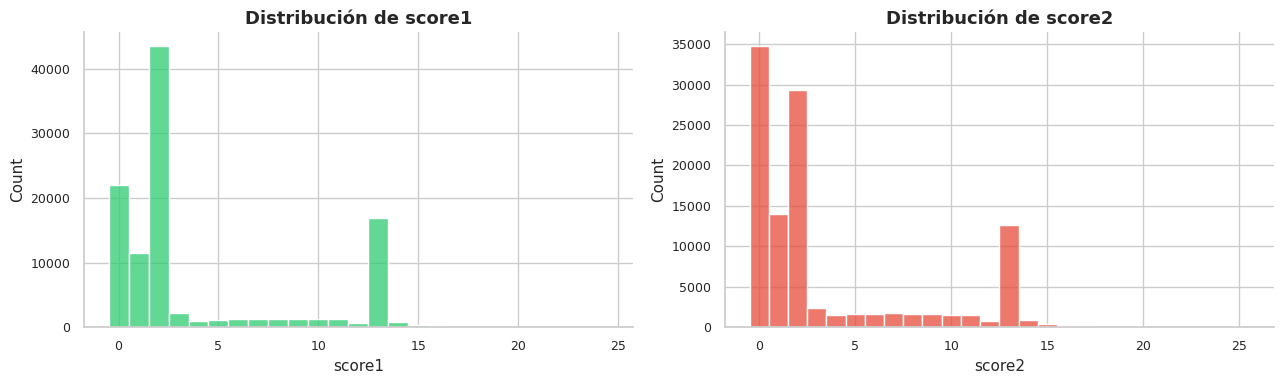

In [6]:
print("=== score1 / score2 (describe) ===")
print(matches[["score1", "score2"]].describe().round(2).to_string())

s1, s2 = matches["score1"], matches["score2"]
es_mapa = (s1 <= 3) & (s2 <= 3)
print(f"\nMarcador de mapas (ambos <= 3): {es_mapa.sum():,} ({es_mapa.mean():.1%})")
print(f"Marcador de rondas (alguno > 3): {(~es_mapa).sum():,} ({1 - es_mapa.mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(matches["score1"], discrete=True, color=COLOR_TEAM1, ax=axes[0])
axes[0].set_title("Distribución de score1")
axes[0].set_xlabel("score1")
sns.histplot(matches["score2"], discrete=True, color=COLOR_TEAM2, ax=axes[1])
axes[1].set_title("Distribución de score2")
axes[1].set_xlabel("score2")
plt.tight_layout()
plt.show()

## 2. Análisis univariado

Cuántos partidos hay por año/mes, qué eventos y equipos dominan el dataset,
y cómo se distribuye el rating/ranking.

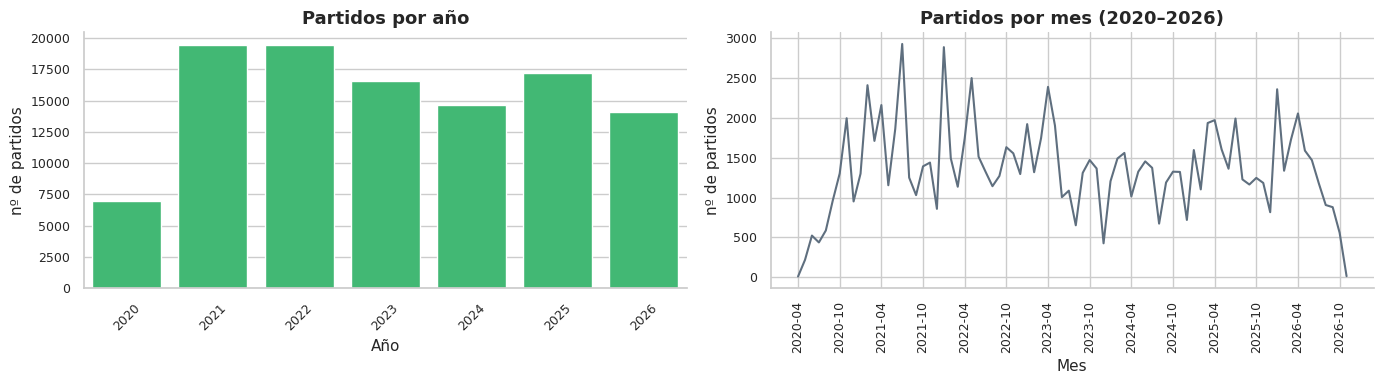

Total de partidos con fecha válida: 108422


In [7]:
dates = parse_dates(matches)
valid = valid_dates_mask(dates)

per_year = dates[valid].dt.year.value_counts().sort_index()
per_month = dates[valid].dt.to_period("M").value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(x=per_year.index.astype(str), y=per_year.values, color=COLOR_TEAM1, ax=axes[0])
axes[0].set_title("Partidos por año")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("nº de partidos")
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(per_month.index.astype(str), per_month.values, color=COLOR_NEUTRAL)
axes[1].set_title("Partidos por mes (2020–2026)")
axes[1].set_xlabel("Mes")
axes[1].set_ylabel("nº de partidos")
axes[1].set_xticks(range(0, len(per_month), 6))
axes[1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

print("Total de partidos con fecha válida:", int(valid.sum()))

Eventos únicos: 2992


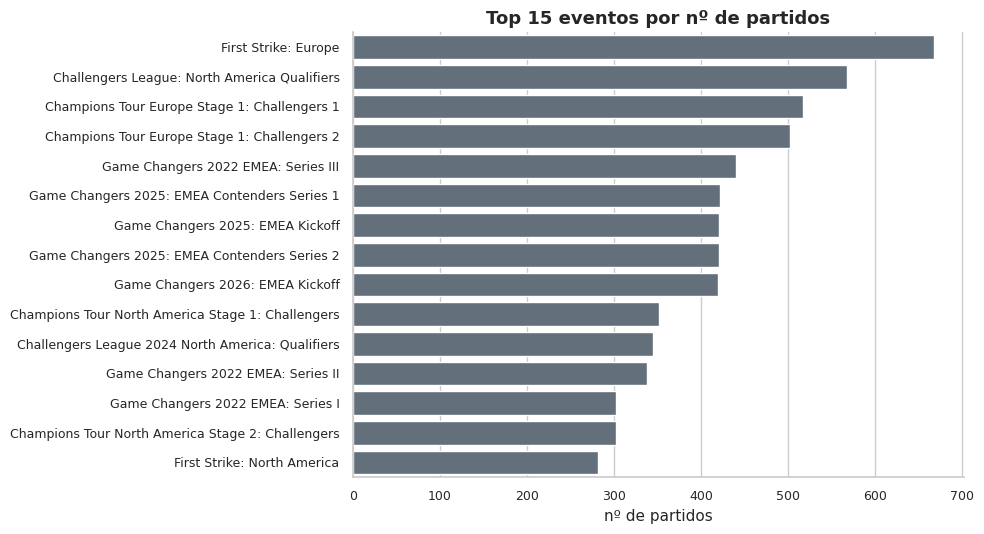

In [8]:
top_events = matches["event"].value_counts().head(15)
print("Eventos únicos:", matches["event"].nunique())

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(y=top_events.index, x=top_events.values, color=COLOR_NEUTRAL, ax=ax)
ax.set_title("Top 15 eventos por nº de partidos")
ax.set_xlabel("nº de partidos")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Equipos únicos en el dataset: 20902


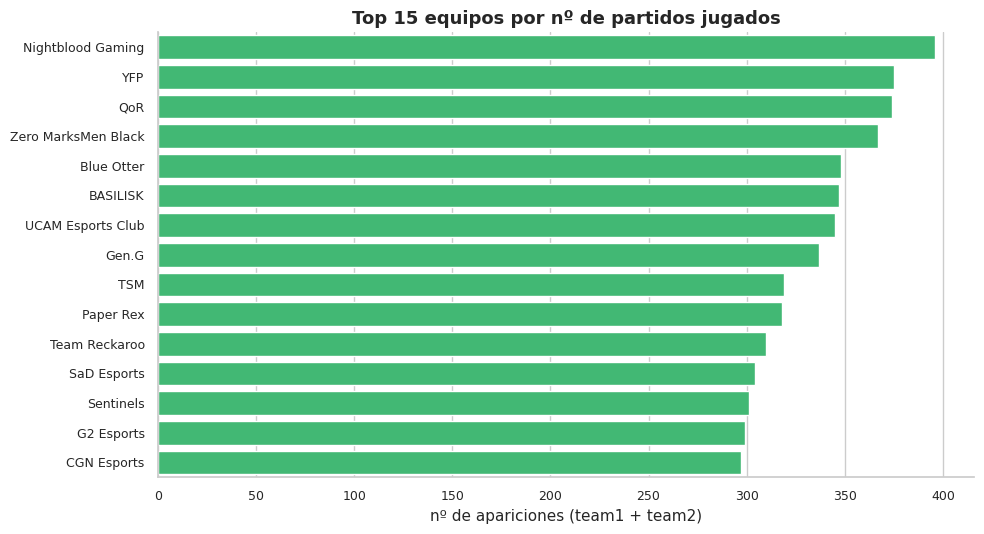

In [9]:
all_teams = Counter(list(matches["team1"]) + list(matches["team2"]))
top_teams = pd.Series(all_teams).sort_values(ascending=False).head(15)
print("Equipos únicos en el dataset:", len(all_teams))

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(y=top_teams.index, x=top_teams.values, color=COLOR_TEAM1, ax=ax)
ax.set_title("Top 15 equipos por nº de partidos jugados")
ax.set_xlabel("nº de apariciones (team1 + team2)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

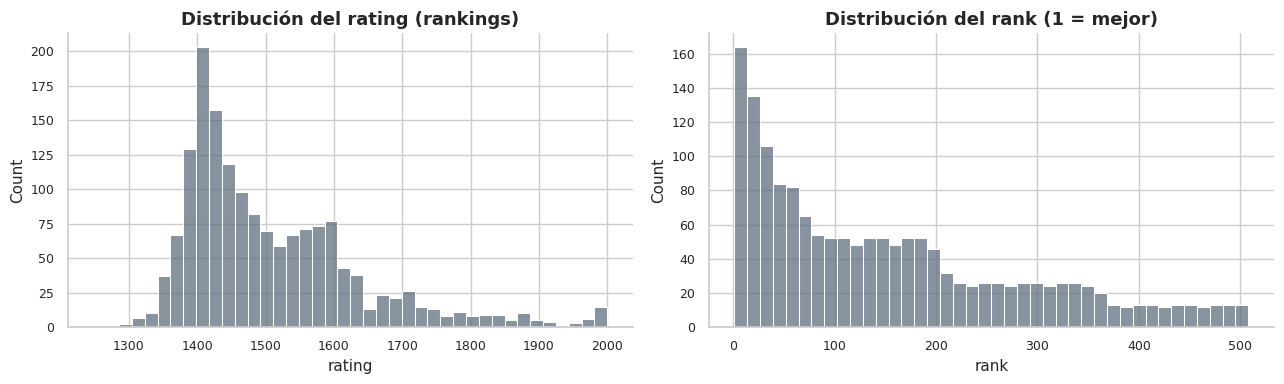

count    1614.0
mean     1508.2
std       131.1
min      1248.0
25%      1412.0
50%      1470.0
75%      1572.8
max      2000.0

Equipos rankeados: 1614 de 1614
Regiones (top 8): {'gc': 508, 'eu': 362, 'na': 209, 'ap': 201, 'col': 83, 'br': 61, 'oce': 58, 'mn': 38}


In [10]:
rankings["rating_num"] = pd.to_numeric(rankings["rating"], errors="coerce")
rankings["rank_num"] = pd.to_numeric(rankings["rank"], errors="coerce")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(rankings["rating_num"], bins=40, color=COLOR_NEUTRAL, ax=axes[0])
axes[0].set_title("Distribución del rating (rankings)")
axes[0].set_xlabel("rating")
sns.histplot(rankings["rank_num"], bins=40, color=COLOR_NEUTRAL, ax=axes[1])
axes[1].set_title("Distribución del rank (1 = mejor)")
axes[1].set_xlabel("rank")
plt.tight_layout()
plt.show()

print(rankings["rating_num"].describe().round(1).to_string())
print("\nEquipos rankeados:", rankings["rank_num"].notna().sum(), "de", len(rankings))
print("Regiones (top 8):", rankings["region"].value_counts().head(8).to_dict())

## 3. Bivariado / señales

Aquí buscamos señales que puedan ayudar a predecir el ganador.

### 3.1 Balance del target `y`

¿Qué proporción de partidos gana `team1`? Un desbalance fuerte condiciona la
métrica y la calibración de probabilidades.

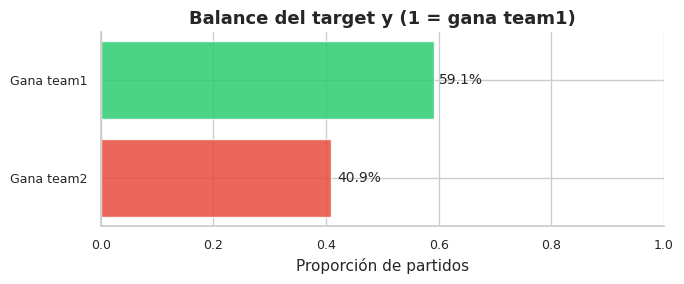

Conteos: {1: 63358, 0: 43884}
team1 gana el 59.1% de los partidos


In [11]:
fig, ax = plt.subplots(figsize=(7, 3))
plot_target_balance(features["y"], ax=ax)
plt.tight_layout()
plt.show()

print("Conteos:", features["y"].value_counts().to_dict())
print(f"team1 gana el {features['y'].mean():.1%} de los partidos")

### 3.2 Win rate por equipo (top / bottom)

Calculamos la win rate global de cada equipo (requiere un mínimo de partidos
para no sesgar con equipos de 1–2 partidos).

In [12]:
wr = win_rate_by_team(features, min_matches=30)

print("=== Mejor win rate (mín. 30 partidos) ===")
print(wr.sort_values("win_rate", ascending=False).head(10)
      [["team", "n", "wins", "win_rate"]].round(3).to_string(index=False))

print("\n=== Peor win rate (mín. 30 partidos) ===")
print(wr.sort_values("win_rate").head(10)
      [["team", "n", "wins", "win_rate"]].round(3).to_string(index=False))

=== Mejor win rate (mín. 30 partidos) ===
                team  n  wins  win_rate
     Vision Strikers 79    74     0.937
 meowwwwwwwwwwwwwwww 38    35     0.921
   Alter Ego Celeste 70    64     0.914
               Arroz 57    51     0.895
          Dark Ratio 45    40     0.889
    Absolute JUPITER 63    56     0.889
STEALING LUNCH MONEY 33    29     0.879
          TERROR.NET 41    36     0.878
      BaosLittleBuns 30    26     0.867
         OREGON HACK 37    32     0.865

=== Peor win rate (mín. 30 partidos) ===
               team  n  wins  win_rate
                LFT 33     1     0.030
           Team TEA 35     4     0.114
        AYM Esports 56     7     0.125
              OCE5N 30     4     0.133
             Aquila 30     5     0.167
  Omnipotent Gaming 97    18     0.186
Skyline Dreamers GC 42     8     0.190
           Eclectiq 36     7     0.194
       Agoge Gaming 41     8     0.195
        THE SHABLES 35     7     0.200


### 3.3 Head-to-head de los 12 equipos con más partidos

Matriz de win rate del equipo de la **fila** contra el de la **columna**.
Celda vacía = no se han enfrentado. Celdas claras favorecen a la fila.

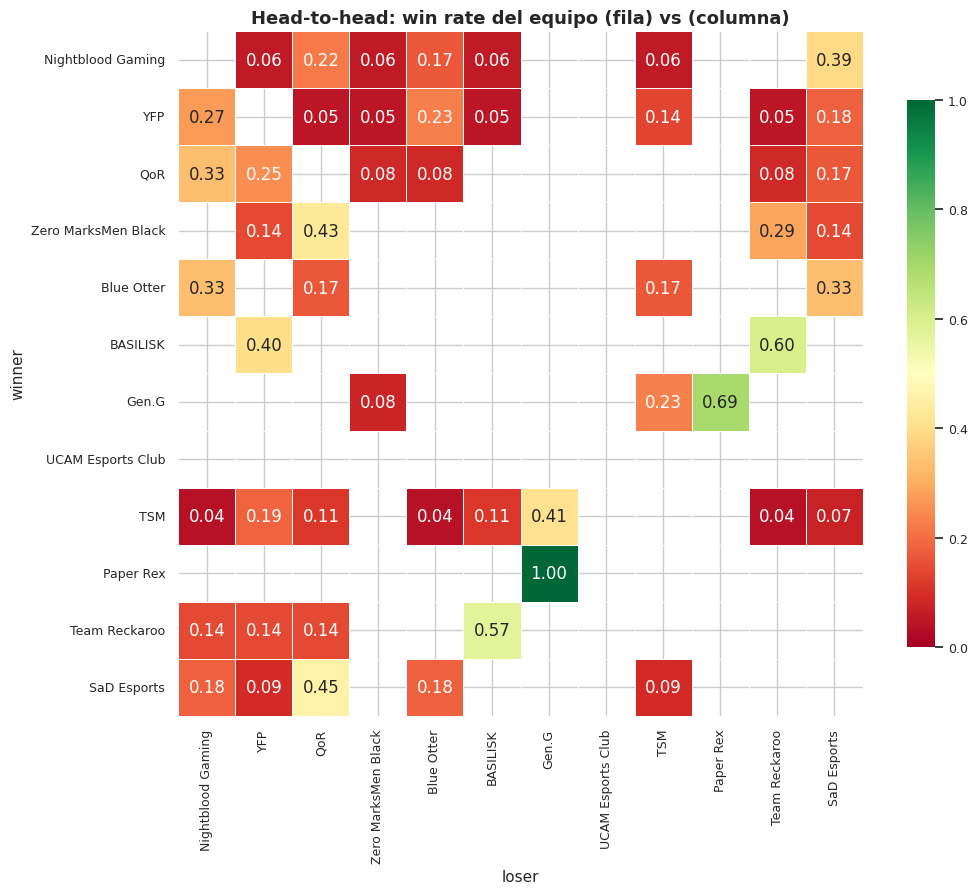

In [13]:
top12 = [t for t, _ in Counter(list(features["team1"]) + list(features["team2"])).most_common(12)]
h2h = head_to_head_matrix(features, top12)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(h2h, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Head-to-head: win rate del equipo (fila) vs (columna)")
plt.tight_layout()
plt.show()

### 3.4 Marcadores más frecuentes (2-0 vs 2-1)

Sobre el subconjunto con marcador de **mapas** (score ≤ 3). El `2-0` domina
claramente sobre el `2-1`: en Valorant los equipos favoritos suelen cerrar
series sin ceder mapa.

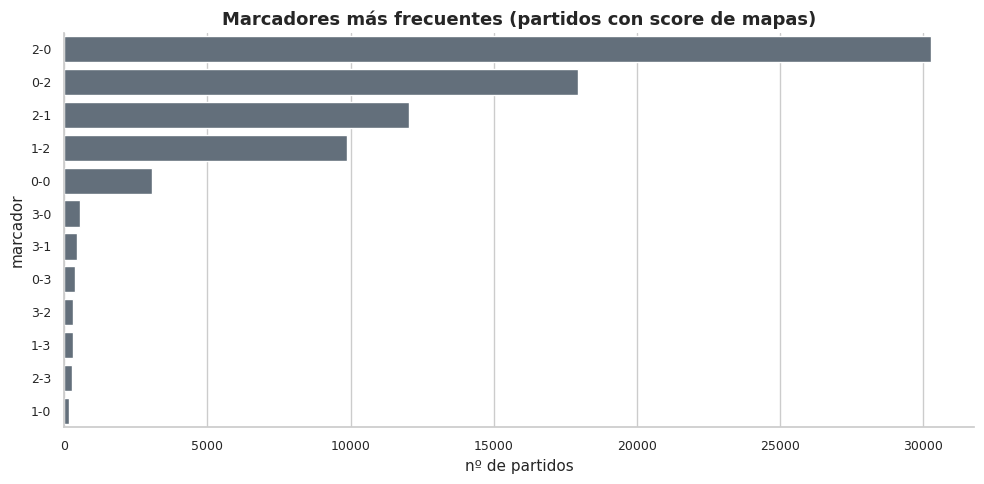

In [14]:
mapmask = (features["score1"] <= 3) & (features["score2"] <= 3)
sub = features[mapmask]
scores = sub.groupby(["score1", "score2"]).size().reset_index(name="n")
scores["marcador"] = (scores["score1"].astype(int).astype(str)
                       + "-" + scores["score2"].astype(int).astype(str))
scores = scores.sort_values("n", ascending=False).head(12)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=scores, y="marcador", x="n", color=COLOR_NEUTRAL, ax=ax)
ax.set_title("Marcadores más frecuentes (partidos con score de mapas)")
ax.set_xlabel("nº de partidos")
ax.set_ylabel("marcador")
plt.tight_layout()
plt.show()

### 3.5 Win rate por mapa (si `team_stats` existe)

Las tablas de equipo aún se están scrapeando. Si `interim/team_stats.parquet`
ya existe y trae `map`/`win_pct`, calculamos el win rate por mapa; si no,
esta celda lo indica y no rompe el flujo.

team_stats disponible: (20124, 14)
['map', 'games', 'win_pct', 'wins', 'losses', 'atk_first', 'def_first', 'atk_rwin_pct', 'atk_rw', 'atk_rl', 'def_rwin_pct', 'def_rw', 'def_rl', 'team_id']


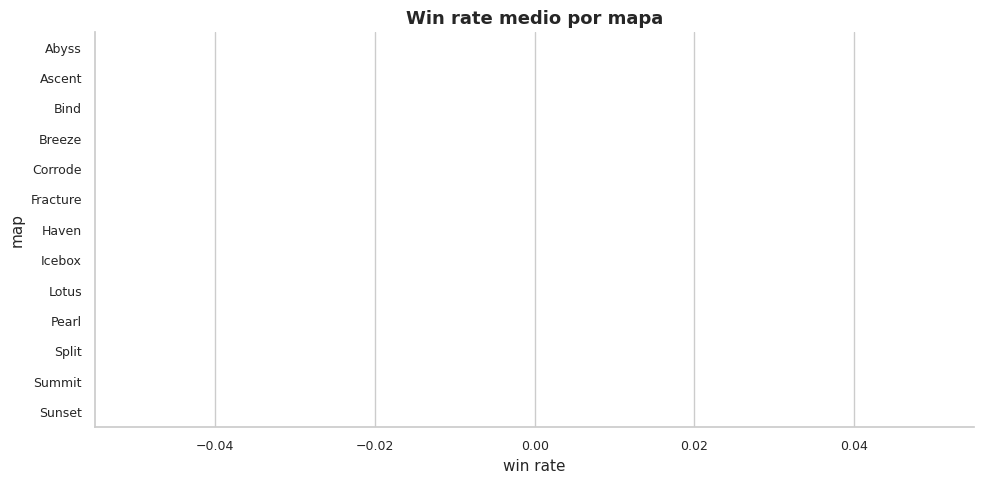

In [15]:
team_stats = tables.get("team_stats")

if team_stats is not None and not team_stats.empty:
    print("team_stats disponible:", team_stats.shape)
    print(team_stats.columns.tolist())
    # heurística defensiva: detectar columnas de mapa y win rate
    map_col = next((c for c in team_stats.columns if "map" in c.lower()), None)
    win_col = next((c for c in team_stats.columns if "win" in c.lower()), None)
    if map_col and win_col:
        ts = team_stats.copy()
        ts[win_col] = pd.to_numeric(ts[win_col], errors="coerce")
        wr_map = ts.groupby(map_col)[win_col].mean().sort_values(ascending=False)
        fig, ax = plt.subplots(figsize=(10, 5))
        sns.barplot(y=wr_map.index, x=wr_map.values, color=COLOR_TEAM1, ax=ax)
        ax.set_title("Win rate medio por mapa")
        ax.set_xlabel("win rate")
        plt.tight_layout()
        plt.show()
    else:
        print("No se encontraron columnas de mapa/win rate claras en team_stats.")
else:
    print("team_stats no está disponible todavía (scraping en curso) → se omite el win rate por mapa.")

## 4. Relación features ↔ target

Usamos `processed/features.parquet` (ya limpio por F3): 12 features `f_*` que
son **diferenciales `team1 − team2`** y el target `y`.

### 4.1 Correlación de cada feature con `y`

Como `y` es binario, la correlación de Pearson es equivalente a una versión
escalada de la correlación punto-biserial y sirve como proxy de fuerza de señal.

Features detectadas: ['f_h2h_winrate', 'f_rating_diff', 'f_rank_diff', 'f_form_diff', 'f_winrate_diff', 'f_mapscore_diff', 'f_experience_diff', 'f_rest_diff', 'f_streak_diff', 'f_map_winrate_diff', 'f_profile_rating_diff', 'f_winnings_diff']


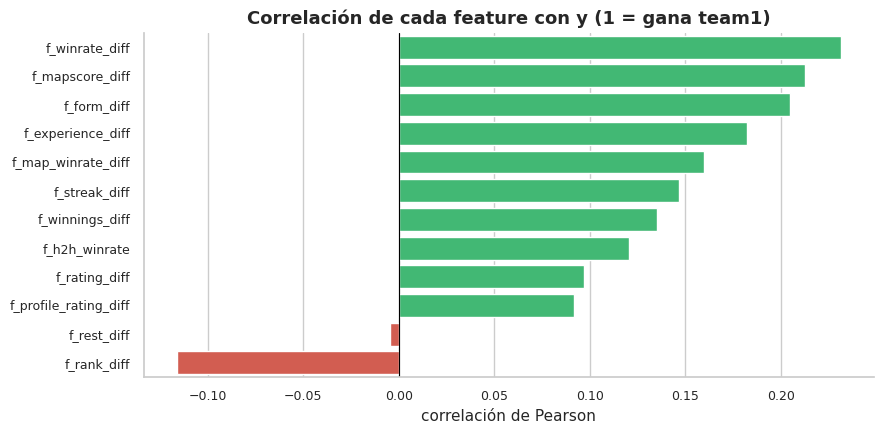

,0
f_winrate_diff,0.2315
f_mapscore_diff,0.2125
f_form_diff,0.2046
f_experience_diff,0.1826
f_map_winrate_diff,0.1599
f_streak_diff,0.1468
f_winnings_diff,0.1351
f_h2h_winrate,0.1207
f_rating_diff,0.0970
f_profile_rating_diff,0.0919


In [16]:
feats = [c for c in features.columns if c.startswith("f_")]
print("Features detectadas:", feats)

corr_y = features[feats].corrwith(features["y"]).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [COLOR_TEAM1 if v >= 0 else COLOR_TEAM2 for v in corr_y.values]
sns.barplot(x=corr_y.values, y=corr_y.index, hue=corr_y.index, palette=colors,
            legend=False, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlación de cada feature con y (1 = gana team1)")
ax.set_xlabel("correlación de Pearson")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

corr_y.round(4)

> Nota: `f_rank_diff` correlaciona **negativo** porque *menor rank = mejor equipo*.
> Su signo negativo es, por tanto, coherente con la señal esperada.

### 4.2 Matriz de correlaciones entre features

Detecta redundancias (features muy correlacionadas entre sí) que convendría
revisar antes de modelar.

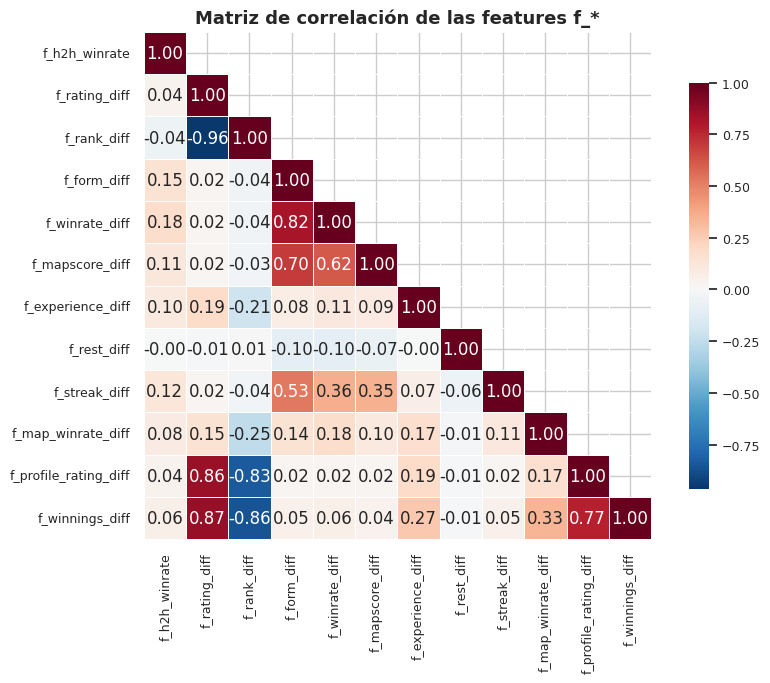

,f_h2h_winrate,f_rating_diff,f_rank_diff,f_form_diff,f_winrate_diff,f_mapscore_diff,f_experience_diff,f_rest_diff,f_streak_diff,f_map_winrate_diff,f_profile_rating_diff,f_winnings_diff
f_h2h_winrate,1.00,0.04,-0.04,0.15,0.18,0.11,0.10,-0.00,0.12,0.08,0.04,0.06
f_rating_diff,0.04,1.00,-0.96,0.02,0.02,0.02,0.19,-0.01,0.02,0.15,0.86,0.87
f_rank_diff,-0.04,-0.96,1.00,-0.04,-0.04,-0.03,-0.21,0.01,-0.04,-0.25,-0.83,-0.86
f_form_diff,0.15,0.02,-0.04,1.00,0.82,0.70,0.08,-0.10,0.53,0.14,0.02,0.05
f_winrate_diff,0.18,0.02,-0.04,0.82,1.00,0.62,0.11,-0.10,0.36,0.18,0.02,0.06
f_mapscore_diff,0.11,0.02,-0.03,0.70,0.62,1.00,0.09,-0.07,0.35,0.10,0.02,0.04
f_experience_diff,0.10,0.19,-0.21,0.08,0.11,0.09,1.00,-0.00,0.07,0.17,0.19,0.27
f_rest_diff,-0.00,-0.01,0.01,-0.10,-0.10,-0.07,-0.00,1.00,-0.06,-0.01,-0.01,-0.01
f_streak_diff,0.12,0.02,-0.04,0.53,0.36,0.35,0.07,-0.06,1.00,0.11,0.02,0.05
f_map_winrate_diff,0.08,0.15,-0.25,0.14,0.18,0.10,0.17,-0.01,0.11,1.00,0.17,0.33


In [17]:
corr = features[feats].corr()
plot_corr_heatmap(corr, "Matriz de correlación de las features f_*")
plt.show()
corr.round(2)

### 4.3 Distribución de features clave por target

Violin plots de cada feature segmentada por `y`. Si la mediana/distribución se
desplaza entre `y=0` y `y=1`, la feature separa ganadores de perdedores.

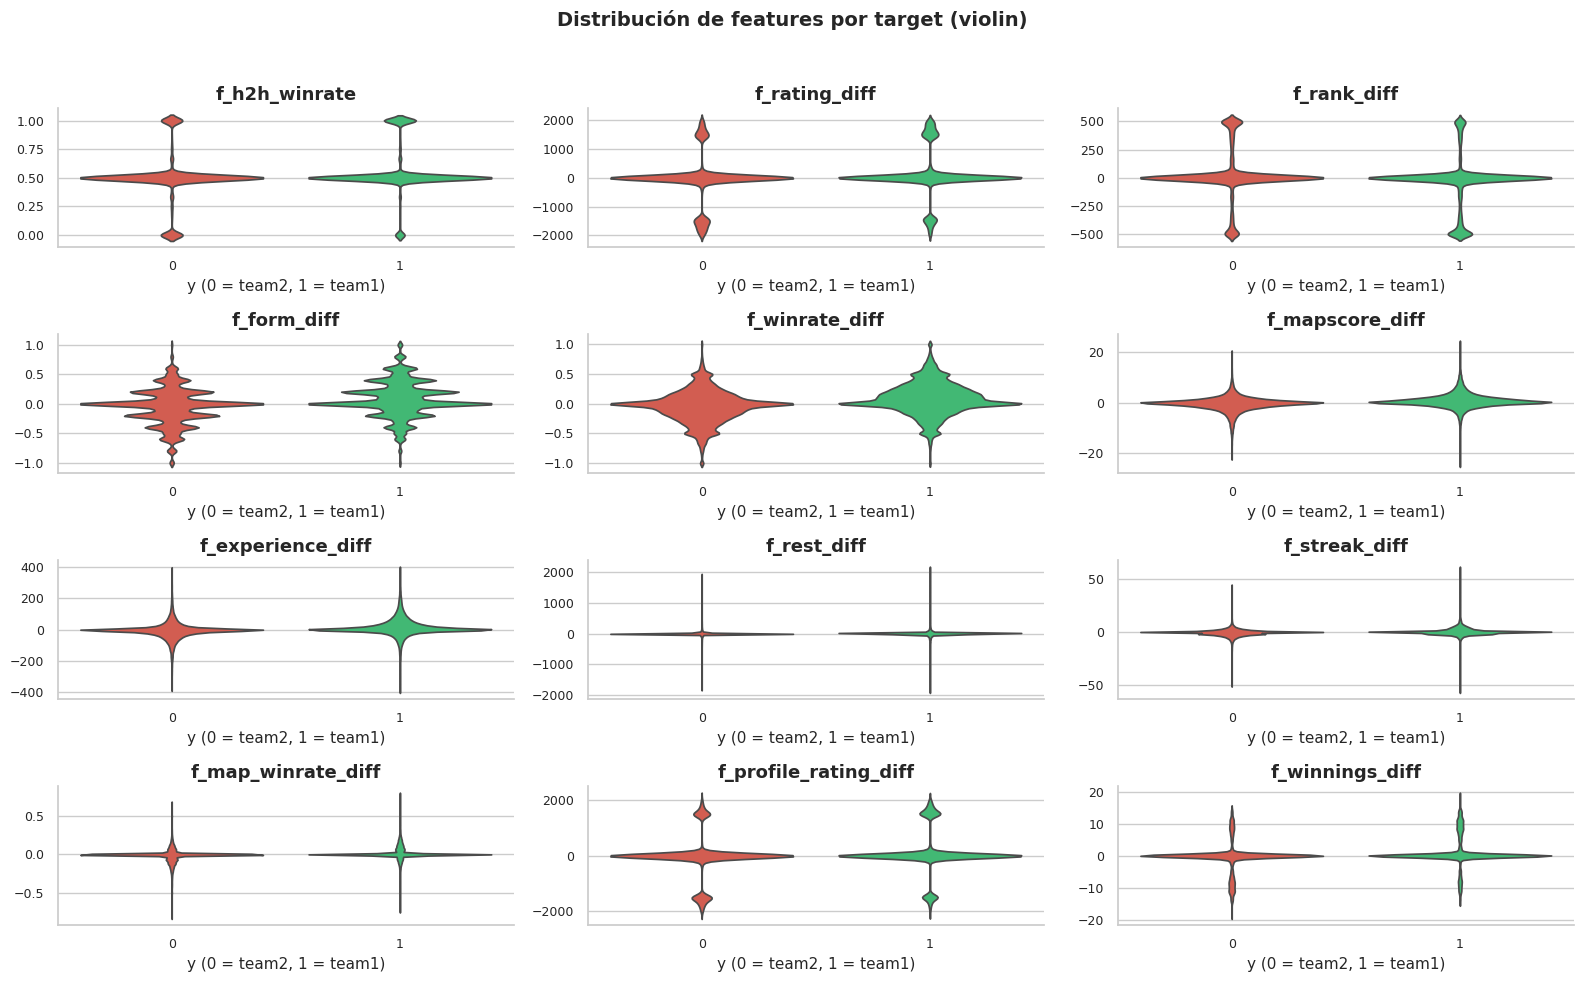

In [18]:
plot_feature_vs_target(features, feats, target="y", kind="violin")
plt.show()

## 5. Conclusiones preliminares

### Hallazgos clave

1. **Desbalance leve del target**: `team1` gana el ~59% de los partidos (no 50%).
   Sugiere un sesgo de ordenación (favorito/seed suele ir primero) más que un
   problema grave; aun así conviene vigilarlo con métricas de calibración.

2. **Los scores mezclan mapas y rondas**: ~30% de los partidos tienen marcador de
   rondas (BO1, hasta 13–25) y ~70% de mapas (BO3/BO5, 0–3). Cualquier feature
   basada en el **margen de score** (`f_mapscore_diff`) mezcla ambas escalas y
   es interpretable con cautela.

3. **Las features históricas dominan sobre el ranking**: las correlaciones con `y`
   más altas son `f_winrate_diff` (0.23), `f_mapscore_diff` (0.21) y `f_form_diff`
   (0.20). `f_rating_diff` (0.10) y `f_rank_diff` (−0.12) aportan menos.

4. **El rating/rank es una señal dispersa**: solo ~1.600 equipos están rankeados
   frente a ~20.900 equipos únicos, por lo que `f_rating_diff`/`f_rank_diff` son 0
   (empate) en la mayoría de partidos. Además son una *foto actual* (no histórica).

5. **Fuerte estratificación de nivel**: los equipos top tienen win rates > 0.85
   (ej. Vision Strikers 0.94, Alter Ego Celeste 0.91) y los peores < 0.2, y el marcador dominante es
   `2-0` (el doble que `2-1`), lo que confirma que la **dominancia** (no solo ganar)
   es informativa.

### Sugerencias para F3/F4

- **F3**: normalizar el margen de score según BO1 vs BO3 (o añadir un flag
  `es_bo1`) para que `f_mapscore_diff` no mezcle escalas.
- **F3**: considerar *ranking histórico* (si se puede scrapear) para eliminar el
  sesgo de "foto actual" de `f_rating_diff`/`f_rank_diff`.
- **F3**: las features más prometedoras son forma/winrate/margen reciente y H2H;
  `f_rest_diff` (descanso) apenas correlaciona (−0.004) y podría descartarse.
- **F4**: usar **split temporal** (ya se conserva `date_ts`), vigilar la
   calibración (Brier/log-loss) por el desbalance, y validar el impacto de quitar
   `f_rating_diff`/`f_rank_diff` para medir cuánto aporta la foto actual.
- **F4**: ante el desbalance, comparar `class_weight` o usar ROC-AUC/Brier como
   métrica principal en lugar de accuracy puro.